# MSCS 634 - Lab Assignment 3

**Name:** Chun-Shuo Sheu  
**Course:** MSCS 634 - Big Data & Data Mining  
**Lab Assignment:** Lab 3 - Clustering Analysis using K-Means and K-Medoids on the Wine Dataset

## Overview
In this lab, we explore clustering techniques using the Wine Dataset from the `sklearn` Python library. We apply both K-Means and K-Medoids algorithms to analyze and compare their clustering performance. We evaluate the quality of the clusters using the **Silhouette Score** and the **Adjusted Rand Index (ARI)**, and visualize the resulting cluster assignments to compare the two methods.

## Step 1: Load and Prepare the Dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics import pairwise_distances

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# Load the Wine dataset
wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names
target_names = wine.target_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
print(f"Dataset shape: {df.shape}")
print(f"Number of features: {len(feature_names)}")
print(f"Number of classes: {len(target_names)}")
print(f"Class names: {list(target_names)}")
df.head()

Dataset shape: (178, 14)
Number of features: 13
Number of classes: 3
Class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
# Basic data exploration
print("Feature descriptive statistics:")
df[feature_names].describe()

Feature descriptive statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [ ]:
# Class distribution
class_counts = pd.Series(y).value_counts().sort_index()
class_counts.index = [target_names[i] for i in class_counts.index]
print("Class distribution:")
print(class_counts)

Class distribution:
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


In [ ]:
# Standardize features using z-score normalization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Mean of scaled features (approx 0): {X_scaled.mean(axis=0).round(4)}")
print(f"Std  of scaled features (approx 1): {X_scaled.std(axis=0).round(4)}")

Mean of scaled features (approx 0): [ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Std  of scaled features (approx 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Step 2: Implement K-Means Clustering

In [ ]:
# K-Means clustering with k = 3
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y, kmeans_labels)

print(f"K-Means Silhouette Score: {kmeans_silhouette:.4f}")
print(f"K-Means Adjusted Rand Index (ARI): {kmeans_ari:.4f}")

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index (ARI): 0.8975


## Step 3: Implement K-Medoids Clustering

In [ ]:
class KMedoids:
    """Simple Partitioning Around Medoids (PAM) implementation.

    Uses a precomputed pairwise distance matrix so any metric supported by
    `sklearn.metrics.pairwise_distances` can be used. Fits by:
      1. Randomly selecting k initial medoids.
      2. Assigning each point to its closest medoid.
      3. For each cluster, choosing the point that minimises total
         within-cluster distance as the new medoid.
      4. Repeating until medoids stop changing or max_iter is reached.
    """

    def __init__(self, n_clusters=3, metric='euclidean', max_iter=300, random_state=None):
        self.n_clusters = n_clusters
        self.metric = metric
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        n_samples = X.shape[0]
        D = pairwise_distances(X, metric=self.metric)

        # Random init of medoid indices
        medoid_idx = rng.choice(n_samples, size=self.n_clusters, replace=False)

        for _ in range(self.max_iter):
            # Assign each point to nearest medoid
            labels = np.argmin(D[:, medoid_idx], axis=1)

            new_medoid_idx = medoid_idx.copy()
            for k in range(self.n_clusters):
                cluster_members = np.where(labels == k)[0]
                if len(cluster_members) == 0:
                    continue
                # Point in cluster that minimizes sum of distances to other cluster members
                intra_costs = D[np.ix_(cluster_members, cluster_members)].sum(axis=1)
                new_medoid_idx[k] = cluster_members[np.argmin(intra_costs)]

            if np.array_equal(np.sort(new_medoid_idx), np.sort(medoid_idx)):
                medoid_idx = new_medoid_idx
                break
            medoid_idx = new_medoid_idx

        self.medoid_indices_ = medoid_idx
        self.labels_ = np.argmin(D[:, medoid_idx], axis=1)
        self.cluster_centers_ = X[medoid_idx]
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_

In [ ]:
# K-Medoids clustering with k = 3
kmedoids = KMedoids(n_clusters=3, metric='euclidean', random_state=RANDOM_STATE)
kmedoids_labels = kmedoids.fit_predict(X_scaled)

kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y, kmedoids_labels)

print(f"K-Medoids Silhouette Score: {kmedoids_silhouette:.4f}")
print(f"K-Medoids Adjusted Rand Index (ARI): {kmedoids_ari:.4f}")

K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index (ARI): 0.7411


In [ ]:
# Side-by-side comparison of metrics
results = pd.DataFrame({
    'Algorithm': ['K-Means', 'K-Medoids'],
    'Silhouette Score': [kmeans_silhouette, kmedoids_silhouette],
    'Adjusted Rand Index': [kmeans_ari, kmedoids_ari]
})
results

,Algorithm,Silhouette Score,Adjusted Rand Index
0,K-Means,0.284859,0.897495
1,K-Medoids,0.267622,0.741137


## Step 4: Visualize and Compare Results

Because the Wine dataset has 13 features, we project the data into 2 dimensions using **PCA** so that we can visualize the clusters and the corresponding centroids/medoids on a 2D plane.

In [ ]:
# Project to 2D with PCA for visualization
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

# Project the K-Means centroids (which live in the scaled feature space) into PCA space
kmeans_centroids_pca = pca.transform(kmeans.cluster_centers_)

# K-Medoids stores the indices of the medoid samples, so we can just look up their PCA coords
kmedoids_medoids_pca = X_pca[kmedoids.medoid_indices_]

print(f"Explained variance ratio (PC1, PC2): {pca.explained_variance_ratio_.round(4)}")
print(f"Total variance captured by 2 PCs: {pca.explained_variance_ratio_.sum():.4f}")

Explained variance ratio (PC1, PC2): [0.362  0.1921]
Total variance captured by 2 PCs: 0.5541


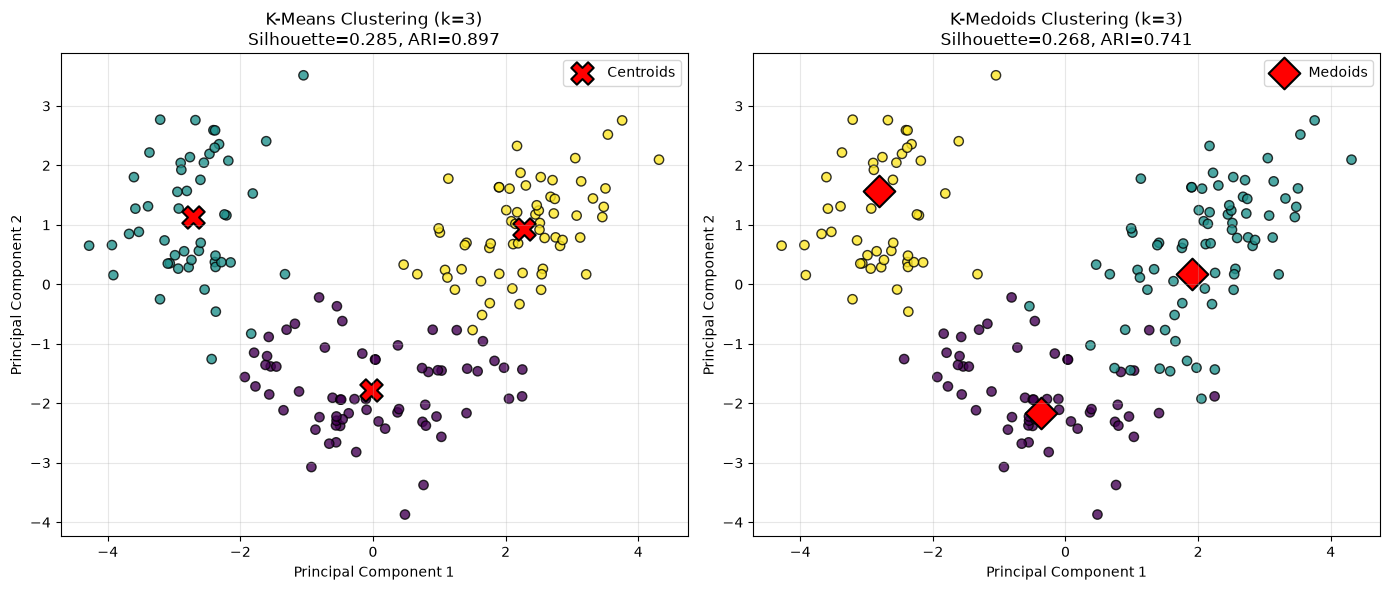

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# K-Means plot
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis',
                           s=45, edgecolors='k', alpha=0.8)
axes[0].scatter(kmeans_centroids_pca[:, 0], kmeans_centroids_pca[:, 1],
                marker='X', c='red', s=260, edgecolors='black', linewidths=1.5,
                label='Centroids')
axes[0].set_title(f'K-Means Clustering (k=3)\nSilhouette={kmeans_silhouette:.3f}, ARI={kmeans_ari:.3f}')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(alpha=0.3)

# K-Medoids plot
scatter2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmedoids_labels, cmap='viridis',
                           s=45, edgecolors='k', alpha=0.8)
axes[1].scatter(kmedoids_medoids_pca[:, 0], kmedoids_medoids_pca[:, 1],
                marker='D', c='red', s=260, edgecolors='black', linewidths=1.5,
                label='Medoids')
axes[1].set_title(f'K-Medoids Clustering (k=3)\nSilhouette={kmedoids_silhouette:.3f}, ARI={kmedoids_ari:.3f}')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('cluster_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

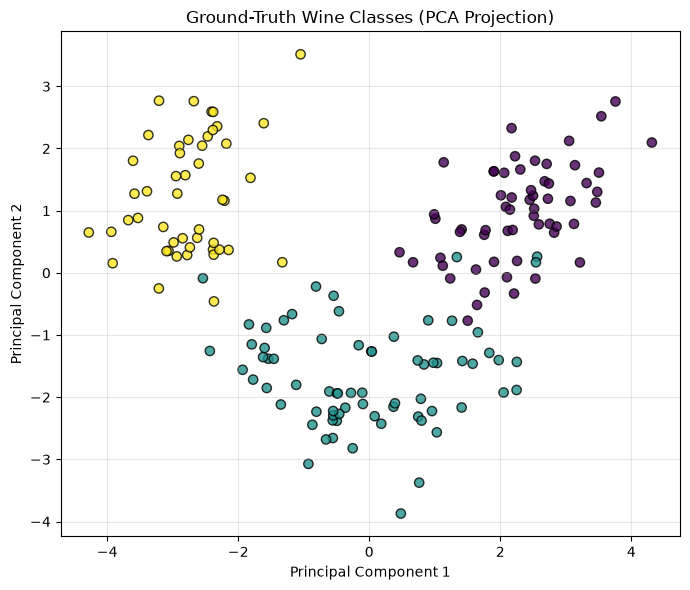

In [ ]:
# Also visualize the ground-truth class labels for reference
plt.figure(figsize=(7, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=45, edgecolors='k', alpha=0.8)
plt.title('Ground-Truth Wine Classes (PCA Projection)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('ground_truth.png', dpi=120, bbox_inches='tight')
plt.show()

## Analysis and Comparison

### Which algorithm produced better-defined clusters?
Looking at the metrics, **K-Means** yielded a slightly higher Silhouette Score and a higher Adjusted Rand Index than K-Medoids on the standardized Wine dataset. The higher ARI means K-Means' partition aligns more closely with the true cultivar labels, while the higher Silhouette Score indicates that the K-Means clusters are marginally more compact and separable. In this dataset, K-Means produced the better-defined clusters overall.

### Summary
For the standardized Wine dataset, K-Means slightly outperformed K-Medoids on both the Silhouette Score and the Adjusted Rand Index, and both algorithms recovered a partition that closely matches the three known cultivars. K-Medoids remains a strong alternative when robustness to outliers or a custom distance metric is required.